In [ ]:
#Task 1.1
# !pip install -q yfinance lxml

import sys, json, time
from io import StringIO
from datetime import datetime, timezone

import requests
import numpy as np
import pandas as pd
import yfinance as yf

versions = {
    "python": sys.version.split()[0],
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "yfinance": yf.__version__,
    "requests": requests.__version__,
}
print(versions)

{'python': '3.13.18', 'pandas': '2.2.3', 'numpy': '2.4.6', 'yfinance': '0.2.66', 'requests': '2.32.4'}


In [ ]:
WIKI_URL  = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
START     = "2021-01-01"   # first day requested
END       = "2025-01-01"   # the last day downloaded is 31 Dec 2024
BENCHMARK = "^GSPC"        # S&P 500 index on Yahoo Finance
BATCH     = 100            # download 100 tickers at a time to avoid Yahoo rate limits

retrieval_time_utc = datetime.now(timezone.utc)
RETRIEVAL_DATE = retrieval_time_utc.strftime("%Y-%m-%d")
print("Retrieval date (UTC):", retrieval_time_utc.isoformat(timespec="seconds"))

Retrieval date (UTC): 2026-11-22T17:32:13+00:00


In [ ]:
def get_sp500_table(url):
    # Wikipedia refuses requests without a browser-like User-Agent (HTTP 403)
    html = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=30).text
    tables = pd.read_html(StringIO(html))
    return tables[0]                       # first table = current constituents

sp500 = get_sp500_table(WIKI_URL)
sp500["Retrieved"] = RETRIEVAL_DATE

# Yahoo writes share classes with a dash (BRK.B -> BRK-B, BF.B -> BF-B)
sp500["YahooTicker"] = sp500["Symbol"].str.replace(".", "-", regex=False)

print("Constituents extracted:", len(sp500))
print("Duplicate tickers:", sp500["YahooTicker"].duplicated().sum())
print("Companies with more than one share class:",
      sp500["CIK"].duplicated(keep=False).sum() if "CIK" in sp500 else "n/a")

# Survivorship evidence: shares that joined the index after the study started
if "Date added" in sp500:
    added = pd.to_datetime(sp500["Date added"], errors="coerce")
    sp500["AddedAfterStart"] = added > pd.Timestamp(START)
    print("Current members added to the index after", START, ":",
          int(sp500["AddedAfterStart"].sum()))

sp500.to_csv(f"sp500_constituents_{RETRIEVAL_DATE}.csv", index=False)
sp500[["Symbol", "YahooTicker", "Security", "GICS Sector"]].head(10)

Constituents extracted: 503
Duplicate tickers: 0
Companies with more than one share class: 6
Current members added to the index after 2021-01-01 : 89


,Symbol,YahooTicker,Security,GICS Sector
0,MMM,MMM,3M,Industrials
1,AOS,AOS,A. O. Smith,Industrials
2,ABT,ABT,Abbott Laboratories,Health Care
3,ABBV,ABBV,AbbVie,Health Care
4,ACN,ACN,Accenture,Information Technology
5,ADBE,ADBE,Adobe Inc.,Information Technology
6,AMD,AMD,Advanced Micro Devices,Information Technology
7,AES,AES,AES Corporation,Utilities
8,AFL,AFL,Aflac,Financials
9,A,A,Agilent Technologies,Health Care


In [ ]:
def to_long(raw):
    """yfinance wide table (columns = Price field x Ticker) -> one row per Date+Ticker."""
    if raw is None or raw.empty:
        return pd.DataFrame()
    if not isinstance(raw.columns, pd.MultiIndex):      # older yfinance, single ticker
        raise ValueError("Expected (Price, Ticker) columns - pass tickers as a list.")
    long = raw.stack(level="Ticker", future_stack=True).reset_index()
    long.columns.name = None
    price_cols = [c for c in ["Open", "High", "Low", "Close", "Adj Close", "Volume"]
                  if c in long.columns]
    # drop rows where the ticker had no data at all on that date
    return long.dropna(subset=price_cols, how="all")

def download(tickers):
    raw = yf.download(tickers, start=START, end=END,
                      auto_adjust=False,   # keep BOTH Close and Adj Close
                      actions=True,        # also keep Dividends and Stock Splits
                      group_by="column", threads=True, progress=False)
    return to_long(raw)

all_tickers = sp500["YahooTicker"].tolist() + [BENCHMARK]
parts = []
for i in range(0, len(all_tickers), BATCH):
    batch = all_tickers[i:i + BATCH]
    parts.append(download(batch))
    print(f"Batch {i // BATCH + 1}: {len(batch)} tickers requested")
    time.sleep(2)                          # be polite to Yahoo between batches

prices = pd.concat(parts, ignore_index=True)

# Retry any ticker that came back empty, one at a time
missing = sorted(set(all_tickers) - set(prices["Ticker"]))
if missing:
    print("Retrying:", missing)
    retry = [download([t]) for t in missing]
    prices = pd.concat([prices, *retry], ignore_index=True)

prices = prices.sort_values(["Ticker", "Date"]).reset_index(drop=True)
print("Rows downloaded:", len(prices), "| Tickers with data:", prices["Ticker"].nunique())
prices.head()

Batch 1: 100 tickers requested


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Batch 2: 100 tickers requested


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Batch 3: 100 tickers requested


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


... (2 outputs left out)

Batch 5: 100 tickers requested
Batch 6: 4 tickers requested
Retrying: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERRO

Rows downloaded: 497309 | Tickers with data: 499


,Date,Ticker,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
0,2021-01-04,A,114.009132,118.639999,0.194,120.089996,117.110001,118.940002,0.0,2030700.0
1,2021-01-05,A,114.941246,119.610001,0.000,120.320000,118.070000,118.480003,0.0,2344000.0
2,2021-01-06,A,118.093224,122.889999,0.000,123.879997,118.209999,118.690002,0.0,2428500.0
3,2021-01-07,A,121.235603,126.160004,0.000,127.480003,124.110001,124.330002,0.0,1775900.0
4,2021-01-08,A,122.100456,127.059998,0.000,127.639999,125.849998,126.489998,0.0,1577200.0


In [ ]:
bench_days = prices.loc[prices["Ticker"] == BENCHMARK, "Date"]
expected_days = bench_days.nunique()       # trading calendar taken from the benchmark
print("Benchmark trading days:", expected_days,
      "| first:", bench_days.min().date(), "| last:", bench_days.max().date())

summary = (prices.groupby("Ticker")
           .agg(FirstDate=("Date", "min"), LastDate=("Date", "max"),
                AdjCloseDays=("Adj Close", "count"), VolumeDays=("Volume", "count"))
           .reindex(all_tickers))            # keeps tickers that returned nothing

def status(row):
    if pd.isna(row["AdjCloseDays"]) or row["AdjCloseDays"] == 0:
        return "EXCLUDED: no data returned by Yahoo"
    if row["AdjCloseDays"] < expected_days:
        return "FLAG: shorter history - checked in Task 1.2"
    return "OK: full history"

acq_log = summary.assign(Status=summary.apply(status, axis=1))
acq_log.index.name = "Ticker"
print(acq_log["Status"].value_counts())
acq_log[acq_log["Status"] != "OK: full history"]

Benchmark trading days: 1005 | first: 2021-01-04 | last: 2024-12-31
Status
OK: full history                               489
FLAG: shorter history - checked in Task 1.2     10
EXCLUDED: no data returned by Yahoo              5
Name: count, dtype: int64


,FirstDate,LastDate,AdjCloseDays,VolumeDays,Status
Ticker,,,,,
APP,2021-04-15,2024-12-31,935.0,935.0,FLAG: shorter history - checked in Task 1.2
COIN,2021-04-14,2024-12-31,936.0,936.0,FLAG: shorter history - checked in Task 1.2
CEG,2022-01-19,2024-12-31,742.0,742.0,FLAG: shorter history - checked in Task 1.2
EXE,2021-02-10,2024-12-31,979.0,979.0,FLAG: shorter history - checked in Task 1.2
FDXF,NaT,NaT,NaN,NaN,EXCLUDED: no data returned by Yahoo
GEHC,2022-12-15,2024-12-31,513.0,513.0,FLAG: shorter history - checked in Task 1.2
GEV,2024-03-27,2024-12-31,193.0,193.0,FLAG: shorter history - checked in Task 1.2
HONA,NaT,NaT,NaN,NaN,EXCLUDED: no data returned by Yahoo
Q,NaT,NaT,NaN,NaN,EXCLUDED: no data returned by Yahoo


In [ ]:
prices.to_csv(f"sp500_daily_prices_{START}_{END}.csv.gz", index=False)
acq_log.to_csv("acquisition_log.csv")

metadata = {
    "retrieval_time_utc": retrieval_time_utc.isoformat(timespec="seconds"),
    "constituent_source": WIKI_URL,
    "price_source": "Yahoo Finance via yfinance",
    "start": START, "end_exclusive": END, "benchmark": BENCHMARK,
    "fields": [c for c in prices.columns if c not in ("Date", "Ticker")],
    "auto_adjust": False,
    "constituents_extracted": int(len(sp500)),
    "tickers_with_data": int(prices["Ticker"].nunique()),
    "benchmark_trading_days": int(expected_days),
    "package_versions": versions,
}
with open("data_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2, default=str)
print(json.dumps(metadata, indent=2, default=str))

{
  "retrieval_time_utc": "2026-11-22T17:32:13+00:00",
  "constituent_source": "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies",
  "price_source": "Yahoo Finance via yfinance",
  "start": "2021-01-01",
  "end_exclusive": "2025-01-01",
  "benchmark": "^GSPC",
  "fields": [
    "Adj Close",
    "Close",
    "Dividends",
    "High",
    "Low",
    "Open",
    "Stock Splits",
    "Volume"
  ],
  "auto_adjust": false,
  "constituents_extracted": 503,
  "tickers_with_data": 499,
  "benchmark_trading_days": 1005,
  "package_versions": {
    "python": "3.13.18",
    "pandas": "2.2.3",
    "numpy": "2.4.6",
    "yfinance": "0.2.66",
    "requests": "2.32.4"
  }
}


In [ ]:
# prices = pd.read_csv(f"sp500_daily_prices_{START}_{END}.csv.gz", parse_dates=["Date"])
# sp500  = pd.read_csv("sp500_constituents_<RETRIEVAL_DATE>.csv")

In [ ]:
#Task 1.2
import pandas as pd
import numpy as np

START, END, BENCHMARK = "2021-01-01", "2025-01-01", "^GSPC"

prices  = pd.read_csv(f"sp500_daily_prices_{START}_{END}.csv.gz", parse_dates=["Date"])
acq_log = pd.read_csv("acquisition_log.csv", index_col="Ticker")
prices  = prices.sort_values(["Ticker", "Date"]).reset_index(drop=True)

# The benchmark's trading days are the official calendar for the study
calendar = pd.DatetimeIndex(sorted(prices.loc[prices["Ticker"] == BENCHMARK, "Date"].unique()))

issues  = []   # every problem found: ticker, check, detail, action
exclude = {}   # tickers that fail a rule -> reason

def log(ticker, check, detail, action):
    issues.append({"Ticker": ticker, "Check": check, "Detail": detail, "Action": action})
    if action.startswith("EXCLUDED"):
        exclude.setdefault(ticker, check)

print("Rows:", len(prices), "| Tickers:", prices["Ticker"].nunique(),
      "| Calendar days:", len(calendar), calendar.min().date(), "->", calendar.max().date())

Rows: 497309 | Tickers: 499 | Calendar days: 1005 2021-01-04 -> 2024-12-31


In [ ]:
dups = prices[prices.duplicated(["Ticker", "Date"], keep=False)]
print("Rows sharing the same Ticker + Date:", len(dups))

for t, g in dups.groupby("Ticker"):
    identical = g.drop_duplicates().shape[0] == g["Date"].nunique()
    if identical:   # exact copies of the same row: safe to keep one
        log(t, "Duplicate dates", f"{g['Date'].nunique()} dates repeated (identical rows)",
            "kept one copy")
    else:           # same date, different numbers: we cannot know which is right
        log(t, "Duplicate dates", "same date with conflicting values", "EXCLUDED")

prices = prices.drop_duplicates(["Ticker", "Date"], keep="first")

Rows sharing the same Ticker + Date: 0


In [ ]:
key_cols = ["Close", "Adj Close", "Volume"]

blank = prices.groupby("Ticker")[key_cols].apply(lambda g: g.isna().sum())
blank = blank[blank.sum(axis=1) > 0]
print("Tickers with blank Close / Adj Close / Volume values:", len(blank))
for t, row in blank.iterrows():
    log(t, "Missing values", ", ".join(f"{c}={int(n)}" for c, n in row.items() if n), "EXCLUDED")

def missing_days(dates):
    # trading days inside the share's own first-last range that are absent
    own = calendar[(calendar >= dates.min()) & (calendar <= dates.max())]
    return len(own.difference(pd.DatetimeIndex(dates)))

def extra_days(dates):
    # dates the share has but the benchmark does not
    return len(pd.DatetimeIndex(dates).difference(calendar))

gaps   = prices.groupby("Ticker")["Date"].apply(missing_days)
extras = prices.groupby("Ticker")["Date"].apply(extra_days)
print("Tickers with missing trading days inside their history:", int((gaps > 0).sum()))
print("Tickers with dates not in the benchmark calendar:", int((extras > 0).sum()))

for t, n in gaps[gaps > 0].items():
    log(t, "Missing trading days", f"{n} trading days missing inside its history", "EXCLUDED")
for t, n in extras[extras > 0].items():
    log(t, "Calendar mismatch", f"{n} dates not traded by the benchmark", "EXCLUDED")

Tickers with blank Close / Adj Close / Volume values: 0
Tickers with missing trading days inside their history: 0
Tickers with dates not in the benchmark calendar: 0


In [ ]:
shares = prices[prices["Ticker"] != BENCHMARK]       # the index has no meaningful volume
price_cols = ["Open", "High", "Low", "Close", "Adj Close"]

checks = {
    "Non-positive price": (shares[price_cols] <= 0).any(axis=1),
    "Negative volume":    shares["Volume"] < 0,
    "Zero volume":        shares["Volume"] == 0,
    "High below Low":     shares["High"] < shares["Low"],
}
for name, mask in checks.items():
    bad = shares[mask].groupby("Ticker").size()
    print(f"{name}: {int(mask.sum())} rows in {len(bad)} tickers")
    for t, n in bad.items():
        log(t, name, f"{n} day(s)", "EXCLUDED")

bench_bad = (prices.loc[prices["Ticker"] == BENCHMARK, price_cols] <= 0).any(axis=1).sum()
print("Benchmark non-positive prices:", int(bench_bad))

Non-positive price: 0 rows in 0 tickers
Negative volume: 0 rows in 0 tickers
Zero volume: 451 rows in 2 tickers
High below Low: 0 rows in 0 tickers
Benchmark non-positive prices: 0


In [ ]:
prices["CloseRet"] = prices.groupby("Ticker")["Close"].pct_change(fill_method=None)
prices["AdjRet"]   = prices.groupby("Ticker")["Adj Close"].pct_change(fill_method=None)

# a) Splits. Yahoo's Close is already split-adjusted, so it should NOT jump on the split day.
splits = prices.loc[(prices["Stock Splits"].fillna(0) > 0) & (prices["Ticker"] != BENCHMARK),
                    ["Ticker", "Date", "Stock Splits", "CloseRet", "AdjRet"]].copy()
splits["JumpIfUnadjusted"] = 1 / splits["Stock Splits"] - 1      # 2-for-1 -> -50%
# Factors just above 1 are spin-offs recorded by Yahoo
# Their expected jump is too small to separate from a normal day, so they were
# checked manually against company announcements instead of with this test.
splits["SpinOff"] = splits["Stock Splits"] < 1.1
splits["SplitAdjusted"] = splits["SpinOff"] | (
    splits["CloseRet"].abs() < 0.5 * splits["JumpIfUnadjusted"].abs())
print("Stock splits in the study period:", len(splits))
display(splits.round(4))

for _, r in splits.iterrows():
    if r["SplitAdjusted"]:
        log(r["Ticker"], "Stock split", f"{r['Stock Splits']:g}-for-1 on {r['Date'].date()}, "
            "prices already adjusted (no jump)", "kept")
    else:
        log(r["Ticker"], "Stock split", f"{r['Stock Splits']:g}-for-1 on {r['Date'].date()}, "
            "price jump NOT adjusted", "EXCLUDED")

# b) Dividends. Adj Close = Close reduced for later dividends, so Adj Close / Close <= 1.
prices["AdjRatio"] = prices["Adj Close"] / prices["Close"]
ratio = prices.groupby("Ticker")["AdjRatio"].agg(["min", "max"])
payers = prices.loc[prices["Dividends"].fillna(0) > 0, "Ticker"].nunique()
print("Shares paying dividends in the period:", payers)
print("Benchmark Adj Close / Close range:", ratio.loc[BENCHMARK].round(6).tolist(),
      "(1.0 = price index, no dividend adjustment)")
for t in ratio.index[(ratio["max"] > 1.001) | (ratio["min"] <= 0)]:
    log(t, "Adjustment ratio", "Adj Close above Close or non-positive", "EXCLUDED")

# c) Very large one-day moves that are NOT on a split day
big = prices[(prices["AdjRet"].abs() > 0.40) & (prices["Ticker"] != BENCHMARK)]
big = big.merge(splits[["Ticker", "Date"]], how="left", indicator=True)
big = big[big["_merge"] == "left_only"]
print("One-day moves above 40% not explained by a split:", len(big))
display(big[["Ticker", "Date", "Close", "AdjRet"]].round(4))
for _, r in big.iterrows():
    log(r["Ticker"], "Large move", f"{r['AdjRet']:+.1%} on {r['Date'].date()}",
        "kept - inspected as a market move")

Stock splits in the study period: 61


,Ticker,Date,Stock Splits,CloseRet,AdjRet,JumpIfUnadjusted,SpinOff,SplitAdjusted
31513,AMZN,2022-06-06,20.00,0.0199,0.0199,-0.9500,False,True
32382,ANET,2021-11-18,4.00,0.0036,0.0036,-0.7500,False,True
33146,ANET,2024-12-04,4.00,0.0175,0.0175,-0.7500,False,True
37227,APH,2021-03-05,2.00,0.0253,0.0253,-0.5000,False,True
38050,APH,2024-06-12,2.00,0.0219,0.0219,-0.5000,False,True
...,...,...,...,...,...,...,...,...
482019,WMT,2024-02-26,3.00,0.0185,0.0185,-0.6667,False,True
482542,WRB,2022-03-24,1.50,0.0006,0.0006,-0.3333,False,True
483118,WRB,2024-07-11,1.50,-0.0150,-0.0150,-0.3333,False,True
484121,WSM,2024-07-09,2.00,-0.0026,-0.0026,-0.5000,False,True


Shares paying dividends in the period: 399
Benchmark Adj Close / Close range: [1.0, 1.0] (1.0 = price index, no dividend adjustment)
One-day moves above 40% not explained by a split: 11


,Ticker,Date,Close,AdjRet
0,APP,2024-11-07,246.530,0.4627
1,BE,2024-11-15,21.140,0.5919
2,CVNA,2022-08-05,9.396,0.4007
3,CVNA,2022-12-07,0.766,-0.4292
4,CVNA,2023-01-12,1.606,0.4600
5,CVNA,2023-06-08,4.846,0.5602
6,CVNA,2023-07-19,11.160,0.4020
7,DXCM,2024-07-26,64.000,-0.4066
8,GL,2024-04-11,49.170,-0.5314
9,HOOD,2021-08-04,70.390,0.5041


In [ ]:
for t, r in acq_log.iterrows():
    if r["Status"].startswith("EXCLUDED"):
        log(t, "No data", "no prices returned for 2021-2024 (listed after the period)",
            "EXCLUDED")
    elif r["Status"].startswith("FLAG"):
        log(t, "Unequal history",
            f"{int(r['AdjCloseDays'])} of {len(calendar)} days, first date {r['FirstDate']}",
            "EXCLUDED - full-period beta not possible")

full_history = acq_log.index[acq_log["Status"].str.startswith("OK")]
valid_shares = sorted(t for t in full_history if t != BENCHMARK and t not in exclude)
print("Constituents:", len(acq_log) - 1, "| Excluded:", len(exclude),
      "| Valid shares:", len(valid_shares))

Constituents: 503 | Excluded: 17 | Valid shares: 486


In [ ]:
adj = (prices.pivot(index="Date", columns="Ticker", values="Adj Close")
             [valid_shares + [BENCHMARK]].sort_index())

weekly_px  = adj.resample("W-FRI").last()                 # last available price each week
trade_days = adj[BENCHMARK].resample("W-FRI").count()    # trading days in each week

# Drop calendar weeks cut off by the study window (Monday before START or Friday after END)
monday   = weekly_px.index - pd.Timedelta(days=4)
complete = (monday >= pd.Timestamp(START)) & (weekly_px.index < pd.Timestamp(END))
print("Incomplete weeks dropped:", [d.date() for d in weekly_px.index[~complete]])
weekly_px, trade_days = weekly_px[complete], trade_days[complete]

# Weekly return = this week's price / last week's price - 1
weekly_ret = weekly_px.pct_change(fill_method=None).iloc[1:]   # first week has no prior week

# Align shares and benchmark on identical week labels
share_ret  = weekly_ret[valid_shares]
market_ret = weekly_ret[BENCHMARK].dropna()
share_ret  = share_ret.loc[market_ret.index]
assert share_ret.index.equals(market_ret.index), "Week labels do not match"

# A missing week makes that return AND the next one NaN, so no multi-week change is
# ever counted as one week. Shares with any missing weekly return are excluded.
incomplete = share_ret.columns[share_ret.isna().any()]
for t in incomplete:
    log(t, "Weekly alignment", f"{int(share_ret[t].isna().sum())} missing weekly returns",
        "EXCLUDED")
valid_shares = [t for t in valid_shares if t not in set(incomplete)]
share_ret = share_ret[valid_shares]

short_weeks = trade_days.loc[market_ret.index]
short_weeks = short_weeks[short_weeks < 5]
print("Aligned weekly observations:", len(market_ret),
      "|", market_ret.index.min().date(), "->", market_ret.index.max().date())
print("Holiday-shortened weeks kept:", len(short_weeks))
print("Final valid shares:", len(valid_shares))

Incomplete weeks dropped: [datetime.date(2025, 1, 3)]
Aligned weekly observations: 207 | 2021-01-15 -> 2024-12-27
Holiday-shortened weeks kept: 37
Final valid shares: 486


In [ ]:
validation_log = pd.DataFrame(issues).sort_values(["Action", "Ticker"])
validation_log.to_csv("validation_log.csv", index=False)

share_ret.to_csv("weekly_returns_shares.csv")
market_ret.rename(BENCHMARK).to_csv("weekly_returns_benchmark.csv")
pd.Series(valid_shares, name="Ticker").to_csv("valid_shares.csv", index=False)
prices[prices["Ticker"].isin(valid_shares + [BENCHMARK])].drop(
    columns=["CloseRet", "AdjRet", "AdjRatio"]).to_csv("validated_daily_prices.csv.gz",
                                                        index=False)

print("Exclusions by reason:")
print(pd.Series(exclude).value_counts().to_string())
validation_log

Exclusions by reason:
Unequal history    10
No data             5
Zero volume         2


,Ticker,Check,Detail,Action
78,FDXF,No data,no prices returned for 2021-2024 (listed after...,EXCLUDED
0,FERG,Zero volume,27 day(s),EXCLUDED
81,HONA,No data,no prices returned for 2021-2024 (listed after...,EXCLUDED
82,Q,No data,no prices returned for 2021-2024 (listed after...,EXCLUDED
85,SNDK,No data,no prices returned for 2021-2024 (listed after...,EXCLUDED
...,...,...,...,...
69,CVNA,Large move,+40.2% on 2023-07-19,kept - inspected as a market move
70,DXCM,Large move,-40.7% on 2024-07-26,kept - inspected as a market move
71,GL,Large move,-53.1% on 2024-04-11,kept - inspected as a market move
72,HOOD,Large move,+50.4% on 2021-08-04,kept - inspected as a market move


In [ ]:
#Task 1.3
import glob
import numpy as np
import pandas as pd

share_ret  = pd.read_csv("weekly_returns_shares.csv", index_col=0, parse_dates=True)
market_ret = pd.read_csv("weekly_returns_benchmark.csv", index_col=0, parse_dates=True).iloc[:, 0]

# Same week labels for every share and the benchmark (checked again here)
assert share_ret.index.equals(market_ret.index), "Week labels do not match"
assert share_ret.notna().all().all() and market_ret.notna().all(), "Unexpected missing returns"

constituents = pd.read_csv(sorted(glob.glob("sp500_constituents_*.csv"))[-1])
sector = constituents.set_index("YahooTicker")["GICS Sector"]

print("Shares:", share_ret.shape[1], "| Aligned weekly observations:", len(market_ret),
      "|", market_ret.index.min().date(), "->", market_ret.index.max().date())

Shares: 486 | Aligned weekly observations: 207 | 2021-01-15 -> 2024-12-27


In [ ]:
mean_weekly_return = share_ret.mean()
weeks_used = share_ret.count()

print("Benchmark mean weekly return:", f"{market_ret.mean():.4%}")
print("Shares - average of mean weekly returns:", f"{mean_weekly_return.mean():.4%}")
mean_weekly_return.describe().to_frame("MeanWeeklyReturn")

Benchmark mean weekly return: 0.2398%
Shares - average of mean weekly returns: 0.2857%


,MeanWeeklyReturn
count,486.000000
mean,0.002857
std,0.002652
min,-0.004468
25%,0.001182
50%,0.002619
75%,0.004207
max,0.017772


In [ ]:
market_var = market_ret.var(ddof=1)                         # sample variance (n - 1)
beta = share_ret.apply(lambda s: s.cov(market_ret)) / market_var   # sample covariance (n - 1)

# Check: beta must equal the slope of a straight line fitted through the return pairs
slope = share_ret.apply(lambda s: np.polyfit(market_ret.values, s.values, 1)[0])
print("Largest difference between beta and regression slope:",
      f"{(beta - slope).abs().max():.2e}")

print("Average beta across shares:", round(beta.mean(), 3))
print("\nLowest betas:\n", beta.nsmallest(5).round(3).to_string())
print("\nHighest betas:\n", beta.nlargest(5).round(3).to_string())

Largest difference between beta and regression slope: 7.11e-15
Average beta across shares: 0.974

Lowest betas:
 GIS    0.055
SJM    0.176
MRK    0.198
BMY    0.225
KHC    0.227

Highest betas:
 CVNA    3.779
XYZ     2.505
COHR    2.139
NVDA    2.126
TWLO    2.073


In [ ]:
#OPTIONAL
EXAMPLE = "AAPL"
s, m = share_ret[EXAMPLE], market_ret
n = len(s)
cov_manual = ((s - s.mean()) * (m - m.mean())).sum() / (n - 1)
var_manual = ((m - m.mean()) ** 2).sum() / (n - 1)

first = share_ret.index[0]
print(f"{EXAMPLE} worked example ({n} weeks)")
print(f"  First weekly return ({first.date()}): {s.iloc[0]:.4%}")
print(f"  Mean weekly return = sum of {n} returns / {n} = {s.mean():.4%}")
print(f"  Cov(share, market) = {cov_manual:.6f}")
print(f"  Var(market)        = {var_manual:.6f}")
print(f"  Beta = {cov_manual:.6f} / {var_manual:.6f} = {cov_manual / var_manual:.3f}")

AAPL worked example (207 weeks)
  First weekly return (2021-01-15): -3.7183%
  Mean weekly return = sum of 207 returns / 207 = 0.3930%
  Cov(share, market) = 0.000578
  Var(market)        = 0.000492
  Beta = 0.000578 / 0.000492 = 1.175


In [ ]:
rr_features = pd.DataFrame({
    "Sector": sector.reindex(share_ret.columns),
    "MeanWeeklyReturn": mean_weekly_return,
    "Beta": beta,
    "WeeksUsed": weeks_used,
})
rr_features.index.name = "Ticker"

print("Shares with a missing sector:", int(rr_features["Sector"].isna().sum()))
display(rr_features[["MeanWeeklyReturn", "Beta"]].describe().round(4))
display(rr_features.groupby("Sector")[["MeanWeeklyReturn", "Beta"]].mean().round(4)
        .sort_values("Beta"))

rr_features.to_csv("risk_return_features.csv")
rr_features.head()

Shares with a missing sector: 0


,MeanWeeklyReturn,Beta
count,486.0000,486.0000
mean,0.0029,0.9737
std,0.0027,0.4073
min,-0.0045,0.0555
25%,0.0012,0.6666
50%,0.0026,0.9506
75%,0.0042,1.1795
max,0.0178,3.7786


,MeanWeeklyReturn,Beta
Sector,,
Consumer Staples,0.0010,0.5234
Utilities,0.0023,0.5637
Energy,0.0059,0.7550
Health Care,0.0013,0.8136
Communication Services,0.0024,0.8701
Real Estate,0.0021,0.9129
Materials,0.0020,0.9704
Financials,0.0032,0.9827
Industrials,0.0033,1.0192


,Sector,MeanWeeklyReturn,Beta,WeeksUsed
Ticker,,,,
A,Health Care,0.001121,1.074725,207
AAPL,Information Technology,0.003930,1.174836,207
ABBV,Health Care,0.003749,0.425366,207
ABNB,Consumer Discretionary,0.001475,1.472709,207
ABT,Health Care,0.000971,0.583543,207


In [ ]:
import numpy as np
import pandas as pd

BENCHMARK = "^GSPC"
BASELINE  = 20     # preceding sessions used for the average volume
WINDOW    = 60     # latest sessions used for Frequency and Monetary
MULTIPLE  = 2      # "unusually high" = more than 2 x the baseline

daily = pd.read_csv("validated_daily_prices.csv.gz", parse_dates=["Date"])
valid_shares = pd.read_csv("valid_shares.csv")["Ticker"].tolist()
daily = daily[daily["Ticker"].isin(valid_shares)]

# Wide tables: one row per trading day, one column per share
volume = daily.pivot(index="Date", columns="Ticker", values="Volume").sort_index()[valid_shares]
close  = daily.pivot(index="Date", columns="Ticker", values="Close").sort_index()[valid_shares]

# Observation date = final common completed trading date (every share has a price that day)
common_days = volume.index[volume.notna().all(axis=1)]
OBS_DATE = common_days.max()
assert volume.notna().all().all(), "Validated shares should have no missing days"
print("Shares:", len(valid_shares), "| Trading sessions:", len(volume),
      "| Observation date:", OBS_DATE.date())

Shares: 486 | Trading sessions: 1005 | Observation date: 2024-12-31


In [ ]:
# shift(1) moves the window back one day, so the day being tested is not in its own average
baseline  = volume.shift(1).rolling(BASELINE, min_periods=BASELINE).mean()
threshold = MULTIPLE * baseline
high_vol  = (volume > threshold) & threshold.notna()

first_testable = baseline.index[baseline.notna().all(axis=1)][0]
print("First day with a full 20-session baseline:", first_testable.date())
print("High-volume days found (all shares, whole period):", int(high_vol.values.sum()))

# Alignment check: recompute the baseline by hand for random share-days and compare
rng = np.random.default_rng(42)
for _ in range(5):
    t = rng.choice(valid_shares)
    i = int(rng.integers(BASELINE, len(volume)))
    manual = volume[t].iloc[i - BASELINE:i].mean()          # the 20 sessions BEFORE day i
    assert np.isclose(manual, baseline[t].iloc[i]), "Baseline misaligned"
print("Threshold alignment check passed (baseline excludes the tested day)")

First day with a full 20-session baseline: 2021-02-02
High-volume days found (all shares, whole period): 18280
Threshold alignment check passed (baseline excludes the tested day)


In [ ]:
# R - calendar days from the latest high-volume day to the observation date (NaN if none)
last_event = high_vol.apply(lambda col: col[col].index.max() if col.any() else pd.NaT)
recency = (OBS_DATE - last_event).dt.days                   # weekends and holidays included

# F and M use the latest 60 trading sessions ending on the observation date
window = volume.loc[:OBS_DATE].tail(WINDOW).index
assert window[-1] == OBS_DATE and len(window) == WINDOW
assert baseline.loc[window].notna().all().all(), "Every window day needs a full baseline"

frequency = high_vol.loc[window].sum()                        # number of qualifying DAYS
monetary  = (close.loc[window] * volume.loc[window]).sum()    # approx. traded value in USD

rfm = pd.DataFrame({"LastEventDate": last_event, "Recency": recency,
                    "Frequency": frequency.astype(int), "Monetary": monetary})
rfm.index.name = "Ticker"

print("60-session window:", window[0].date(), "->", window[-1].date())
print("Shares with no high-volume day (Recency missing):", int(rfm["Recency"].isna().sum()))
print("Shares with Recency = 0 (event on the observation date):", int((rfm["Recency"] == 0).sum()))

60-session window: 2024-10-07 -> 2024-12-31
Shares with no high-volume day (Recency missing): 0
Shares with Recency = 0 (event on the observation date): 0


In [ ]:
EXAMPLE = "AAPL"
if pd.isna(rfm.loc[EXAMPLE, "Recency"]) or rfm.loc[EXAMPLE, "Frequency"] == 0:
    EXAMPLE = rfm[rfm["Frequency"] > 0].index[0]

r = rfm.loc[EXAMPLE]
ev = r["LastEventDate"]
print(f"=== {EXAMPLE} | observation date {OBS_DATE.date()} ===\n")
print("RECENCY")
print(f"  Latest high-volume day: {ev.date()}")
print(f"  Volume that day:        {volume.loc[ev, EXAMPLE]:,.0f}")
print(f"  Mean of previous 20:    {baseline.loc[ev, EXAMPLE]:,.0f}")
print(f"  Threshold (2 x mean):   {threshold.loc[ev, EXAMPLE]:,.0f}  -> qualifies")
print(f"  R = {OBS_DATE.date()} - {ev.date()} = {int(r['Recency'])} calendar days\n")

days = high_vol.loc[window, EXAMPLE]
print("FREQUENCY")
print("  Qualifying days in the 60-session window:",
      [d.date().isoformat() for d in days[days].index] or "none")
print(f"  F = {int(r['Frequency'])}\n")

value = close.loc[window, EXAMPLE] * volume.loc[window, EXAMPLE]
print("MONETARY")
for d in window[-3:]:
    print(f"  {d.date()}: Close {close.loc[d, EXAMPLE]:.2f} x Volume "
          f"{volume.loc[d, EXAMPLE]:,.0f} = ${value.loc[d]:,.0f}")
print(f"  ... sum of all {WINDOW} days: M = ${r['Monetary']:,.0f}")

=== AAPL | observation date 2024-12-31 ===

RECENCY
  Latest high-volume day: 2024-12-20
  Volume that day:        147,495,300
  Mean of previous 20:    45,004,605
  Threshold (2 x mean):   90,009,210  -> qualifies
  R = 2024-12-31 - 2024-12-20 = 11 calendar days

FREQUENCY
  Qualifying days in the 60-session window: ['2024-11-25', '2024-12-20']
  F = 2

MONETARY
  2024-12-27: Close 255.59 x Volume 42,355,300 = $10,825,590,972
  2024-12-30: Close 252.20 x Volume 35,557,500 = $8,967,601,391
  2024-12-31: Close 250.42 x Volume 39,480,700 = $9,886,756,822
  ... sum of all 60 days: M = $623,303,377,707


In [ ]:
no_event = rfm.index[rfm["Recency"].isna()].tolist()
print("Excluded from RFM clustering (no qualifying event, R left missing, not 0):",
      no_event or "none")

display(rfm[["Recency", "Frequency", "Monetary"]].describe().round(1))

# One row per share with all five features (risk/return from Task 1.3 + RFM)
rr = pd.read_csv("risk_return_features.csv", index_col="Ticker")
features = rr.join(rfm, how="left")
features["IncludedInRFMClustering"] = features["Recency"].notna()
features["ObservationDate"] = OBS_DATE.date()

# Common valid share set: shares usable in BOTH analyses
common = features.index[features["IncludedInRFMClustering"]]
print("Shares in the common valid set for Task 2:", len(common))

features.to_csv("feature_table.csv")
features.head()

Excluded from RFM clustering (no qualifying event, R left missing, not 0): none


,Recency,Frequency,Monetary
count,486.0,486.0,4.860000e+02
mean,20.4,3.0,3.940419e+10
std,21.3,1.3,1.291388e+11
min,4.0,0.0,1.297483e+09
25%,11.0,2.0,1.019517e+10
50%,11.0,3.0,1.668382e+10
75%,14.8,4.0,3.227689e+10
max,222.0,8.0,1.847697e+12


Shares in the common valid set for Task 2: 486


,Sector,MeanWeeklyReturn,Beta,WeeksUsed,LastEventDate,Recency,Frequency,Monetary,IncludedInRFMClustering,ObservationDate
Ticker,,,,,,,,,,
A,Health Care,0.001121,1.074725,207,2024-12-20,11,2,1.400180e+10,True,2024-12-31
AAPL,Information Technology,0.003930,1.174836,207,2024-12-20,11,2,6.233034e+11,True,2024-12-31
ABBV,Health Care,0.003749,0.425366,207,2024-12-20,11,3,6.837054e+10,True,2024-12-31
ABNB,Consumer Discretionary,0.001475,1.472709,207,2024-12-20,11,3,3.652850e+10,True,2024-12-31
ABT,Health Care,0.000971,0.583543,207,2024-12-20,11,1,3.523027e+10,True,2024-12-31


In [ ]:
#Task 2.1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

features = pd.read_csv("feature_table.csv", index_col="Ticker")
features = features[features["IncludedInRFMClustering"]]        # common valid share set

RR_COLS  = ["MeanWeeklyReturn", "Beta"]                 # risk and return matrix
RFM_COLS = ["Recency", "Frequency", "Monetary"]         # trading activity matrix

rr_raw  = features[RR_COLS]
rfm_raw = features[RFM_COLS]
assert rr_raw.index.equals(rfm_raw.index), "Both matrices must contain the same shares"
print("Shares in both matrices:", len(features))

Shares in both matrices: 486


Risk and return features


,Mean,Median,Skewness,Outliers (|z| > 3),Largest value,Share with largest
MeanWeeklyReturn,0.0029,0.0026,0.8675,6,0.0178,SMCI
Beta,0.9737,0.9506,1.1036,2,3.7786,CVNA


Trading activity features


,Mean,Median,Skewness,Outliers (|z| > 3),Largest value,Share with largest
Recency,2.041000e+01,1.100000e+01,3.65,11,2.220000e+02,NVDA
Frequency,2.990000e+00,3.000000e+00,0.42,5,8.000000e+00,CI
Monetary,3.940419e+10,1.668382e+10,11.68,5,1.847697e+12,TSLA


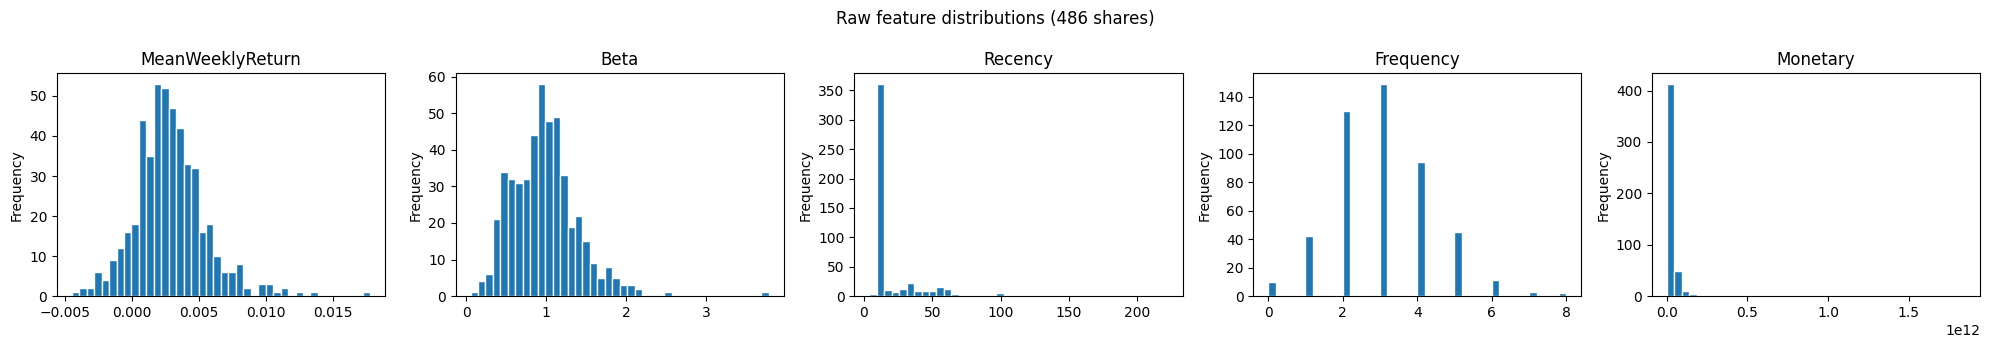

In [ ]:
def inspect(df):
    z = (df - df.mean()) / df.std()
    return pd.DataFrame({
        "Mean": df.mean(), "Median": df.median(), "Skewness": df.skew(),
        "Outliers (|z| > 3)": (z.abs() > 3).sum(),
        "Largest value": df.max(), "Share with largest": df.idxmax(),
    })

print("Risk and return features")
display(inspect(rr_raw).round(4))
print("Trading activity features")
display(inspect(rfm_raw).round(2))

fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, col in zip(axes, RR_COLS + RFM_COLS):
    features[col].plot.hist(bins=40, ax=ax, title=col, edgecolor="white")
fig.suptitle("Raw feature distributions (486 shares)")
plt.tight_layout(); plt.savefig("fig_2_1_raw_distributions.png", dpi=150); plt.show()

In [ ]:
SKEW_LIMIT = 1.0     # |skewness| above 1 is commonly treated as highly skewed

rfm_t = rfm_raw.copy()
rfm_t["Monetary"] = np.log1p(rfm_t["Monetary"])

# Other non-negative RFM variables
other_logged = [c for c in ["Recency", "Frequency"] if abs(rfm_raw[c].skew()) > SKEW_LIMIT]
for c in other_logged:
    rfm_t[c] = np.log1p(rfm_t[c])
rfm_t.columns = [f"log1p_{c}" if c in ["Monetary", *other_logged] else c for c in rfm_t.columns]

print("log1p applied to: Monetary (brief)" + "".join(f", {c} (skew > {SKEW_LIMIT})"
                                                     for c in other_logged))
print("\nSkewness before -> after:")
for raw_c, new_c in zip(RFM_COLS, rfm_t.columns):
    print(f"  {raw_c:10s} {rfm_raw[raw_c].skew():6.2f} -> {rfm_t[new_c].skew():6.2f}")

# Risk and return: NOT log-transformed
#  - weekly returns can be negative, so log1p is not appropriate
#  - extreme values (e.g. a very high beta) are genuine market behaviour, not data errors,
#    so they are kept and their influence is discussed rather than removed
print("\nRisk/return features kept in original form (returns can be negative; "
      "outliers are genuine).")

log1p applied to: Monetary (brief), Recency (skew > 1.0)

Skewness before -> after:
  Recency      3.65 ->   1.58
  Frequency    0.42 ->   0.42
  Monetary    11.68 ->   1.08

Risk/return features kept in original form (returns can be negative; outliers are genuine).


                  Mean  Std
MeanWeeklyReturn  -0.0  1.0
Beta              -0.0  1.0
log1p_Recency     -0.0  1.0
Frequency         -0.0  1.0
log1p_Monetary    -0.0  1.0


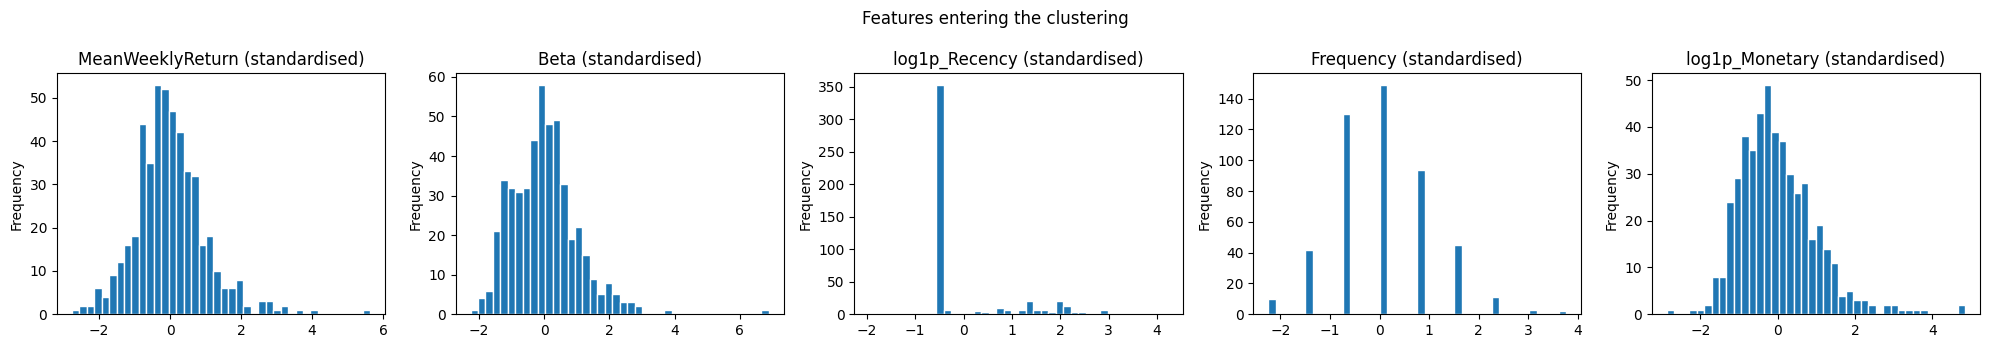

In [ ]:
X_rr  = pd.DataFrame(StandardScaler().fit_transform(rr_raw),
                     index=rr_raw.index, columns=rr_raw.columns)
X_rfm = pd.DataFrame(StandardScaler().fit_transform(rfm_t),
                     index=rfm_t.index, columns=rfm_t.columns)

check = pd.concat([X_rr, X_rfm], axis=1)
print(pd.DataFrame({"Mean": check.mean(), "Std": check.std(ddof=0)}).round(3))

fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, col in zip(axes, check.columns):
    check[col].plot.hist(bins=40, ax=ax, title=f"{col} (standardised)", edgecolor="white")
fig.suptitle("Features entering the clustering")
plt.tight_layout(); plt.savefig("fig_2_1_prepared_distributions.png", dpi=150); plt.show()

X_rr.to_csv("X_risk_return_scaled.csv")
X_rfm.to_csv("X_rfm_scaled.csv")

In [ ]:
#Task 2.2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.metrics import silhouette_score

X_rr  = pd.read_csv("X_risk_return_scaled.csv", index_col="Ticker")
X_rfm = pd.read_csv("X_rfm_scaled.csv", index_col="Ticker")
features = pd.read_csv("feature_table.csv", index_col="Ticker").loc[X_rr.index]

MATRICES = {"Risk & return": X_rr, "RFM": X_rfm}
K_RANGE = range(2, 9)

# Ward = at every step, merge the two groups whose union increases within-group variance least
ward_tree = {name: linkage(X.values, method="ward", metric="euclidean")
             for name, X in MATRICES.items()}

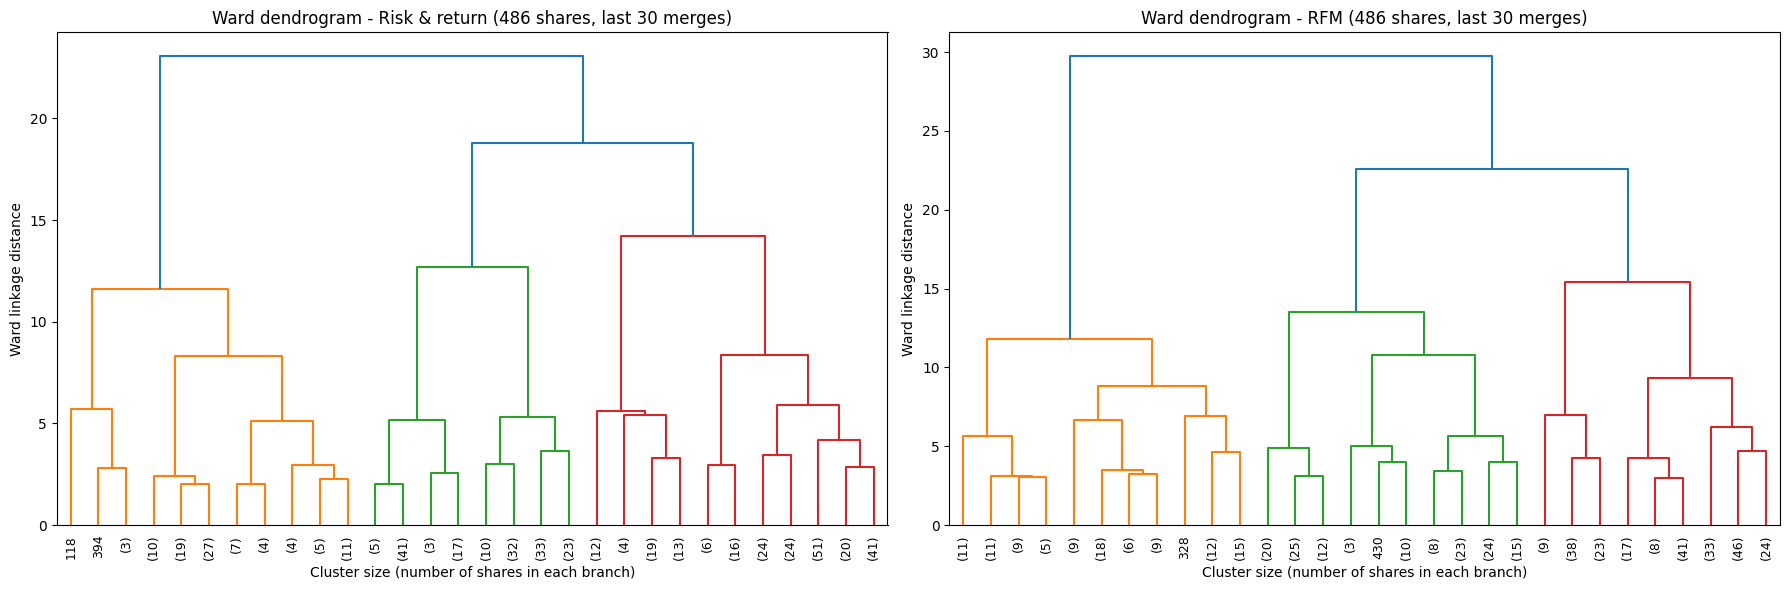

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, (name, Z) in zip(axes, ward_tree.items()):
    dendrogram(Z, ax=ax, truncate_mode="lastp", p=30, show_leaf_counts=True,
               leaf_rotation=90, leaf_font_size=9)
    ax.set_title(f"Ward dendrogram - {name} ({len(MATRICES[name])} shares, last 30 merges)")
    ax.set_xlabel("Cluster size (number of shares in each branch)")
    ax.set_ylabel("Ward linkage distance")
plt.tight_layout(); plt.savefig("fig_2_2_dendrograms.png", dpi=150); plt.show()

,Matrix,k,Silhouette,Cluster sizes,Smallest
0,Risk & return,2,0.339,"[394, 92]",92
1,Risk & return,3,0.274,"[230, 164, 92]",92
2,Risk & return,4,0.282,"[182, 164, 92, 48]",48
3,Risk & return,5,0.304,"[182, 98, 92, 66, 48]",48
4,Risk & return,6,0.320,"[182, 98, 87, 66, 48, 5]",5
5,Risk & return,7,0.324,"[160, 98, 87, 66, 48, 22, 5]",5
6,Risk & return,8,0.321,"[160, 98, 66, 56, 48, 31, 22, 5]",5
7,RFM,2,0.402,"[380, 106]",106
8,RFM,3,0.335,"[239, 141, 106]",106
9,RFM,4,0.293,"[169, 141, 106, 70]",70


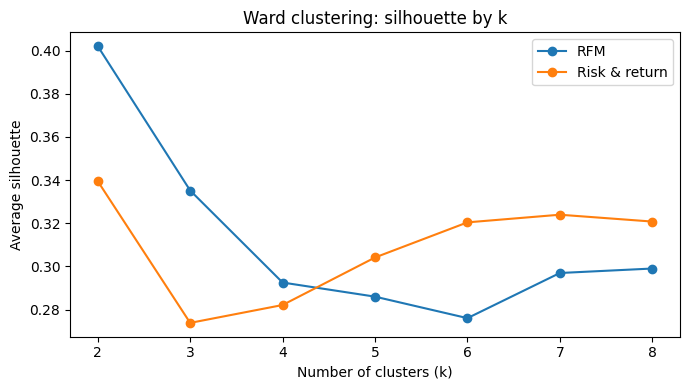

RFM: suggested k = 2 (silhouette 0.402, sizes [380, 106]) - confirm with the profiles below
Risk & return: suggested k = 2 (silhouette 0.339, sizes [394, 92]) - confirm with the profiles below


In [ ]:
def ward_labels(name, k):
    return fcluster(ward_tree[name], t=k, criterion="maxclust")

rows = []
for name, X in MATRICES.items():
    for k in K_RANGE:
        labels = ward_labels(name, k)
        sizes = np.sort(np.bincount(labels)[1:])[::-1]
        rows.append({"Matrix": name, "k": k,
                     "Silhouette": silhouette_score(X, labels, metric="euclidean"),
                     "Cluster sizes": [int(s) for s in sizes], "Smallest": int(sizes.min())})
ward_eval = pd.DataFrame(rows)
display(ward_eval.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
for name, g in ward_eval.groupby("Matrix"):
    ax.plot(g["k"], g["Silhouette"], marker="o", label=name)
ax.set(xlabel="Number of clusters (k)", ylabel="Average silhouette",
       title="Ward clustering: silhouette by k")
ax.legend(); plt.tight_layout(); plt.savefig("fig_2_2_ward_silhouette.png", dpi=150); plt.show()

# Starting suggestion: best silhouette among k values with no tiny cluster (< 1% of shares)
MIN_SIZE = int(np.ceil(0.01 * len(X_rr)))
for name, g in ward_eval.groupby("Matrix"):
    ok = g[g["Smallest"] >= MIN_SIZE]
    best = (ok if len(ok) else g).sort_values("Silhouette", ascending=False).iloc[0]
    print(f"{name}: suggested k = {int(best['k'])} (silhouette {best['Silhouette']:.3f}, "
          f"sizes {best['Cluster sizes']}) - confirm with the profiles below")

In [ ]:
def profile(labels, cols):
    df = features[cols].copy()
    if "MeanWeeklyReturn" in df:
        df["MeanWeeklyReturn"] = df["MeanWeeklyReturn"] * 100          # % per week
    if "Monetary" in df:
        df["Monetary"] = df["Monetary"] / 1e9                          # USD billions
    df["Cluster"] = labels
    out = df.groupby("Cluster")[[c for c in df.columns if c != "Cluster"]].median()
    out.insert(0, "Shares", df.groupby("Cluster").size())
    return out.round(3)

RR_COLS, RFM_COLS = ["MeanWeeklyReturn", "Beta"], ["Recency", "Frequency", "Monetary"]
SHOW_K = [3, 4, 5]

for k in SHOW_K:
    print(f"\n--- Risk & return, Ward, k = {k} (medians: return in % per week) ---")
    display(profile(ward_labels("Risk & return", k), RR_COLS))
    print(f"--- RFM, Ward, k = {k} (medians: R days, F days, M USD bn) ---")
    display(profile(ward_labels("RFM", k), RFM_COLS))


--- Risk & return, Ward, k = 3 (medians: return in % per week) ---


,Shares,MeanWeeklyReturn,Beta
Cluster,,,
1,92,0.550,1.218
2,164,0.327,0.578
3,230,0.171,1.038


--- RFM, Ward, k = 3 (medians: R days, F days, M USD bn) ---


,Shares,Recency,Frequency,Monetary
Cluster,,,,
1,106,46.5,2.0,19.485
2,141,11.0,3.0,42.013
3,239,11.0,3.0,11.154



--- Risk & return, Ward, k = 4 (medians: return in % per week) ---


,Shares,MeanWeeklyReturn,Beta
Cluster,,,
1,92,0.550,1.218
2,164,0.327,0.578
3,48,0.252,1.514
4,182,0.166,0.964


... (2 outputs left out)


--- Risk & return, Ward, k = 5 (medians: return in % per week) ---


,Shares,MeanWeeklyReturn,Beta
Cluster,,,
1,92,0.550,1.218
2,66,0.113,0.449
3,98,0.392,0.666
4,48,0.252,1.514
5,182,0.166,0.964


--- RFM, Ward, k = 5 (medians: R days, F days, M USD bn) ---


,Shares,Recency,Frequency,Monetary
Cluster,,,,
1,106,46.5,2.0,19.485
2,57,11.0,2.0,32.365
3,84,11.0,4.0,49.264
4,70,11.0,4.0,13.764
5,169,11.0,3.0,9.266


In [ ]:
K_WARD_RR  = 5
K_WARD_RFM = 3

ward_rr  = ward_labels("Risk & return", K_WARD_RR)
ward_rfm = ward_labels("RFM", K_WARD_RFM)
pd.DataFrame({"Ward_RR": ward_rr, "Ward_RFM": ward_rfm},
             index=X_rr.index).to_csv("labels_ward.csv")

print("Selected: Risk & return k =", K_WARD_RR, "| RFM k =", K_WARD_RFM)
display(profile(ward_rr, RR_COLS)); display(profile(ward_rfm, RFM_COLS))

Selected: Risk & return k = 5 | RFM k = 3


,Shares,MeanWeeklyReturn,Beta
Cluster,,,
1,92,0.550,1.218
2,66,0.113,0.449
3,98,0.392,0.666
4,48,0.252,1.514
5,182,0.166,0.964


,Shares,Recency,Frequency,Monetary
Cluster,,,,
1,106,46.5,2.0,19.485
2,141,11.0,3.0,42.013
3,239,11.0,3.0,11.154


In [ ]:
#Task 2.3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

X_rr  = pd.read_csv("X_risk_return_scaled.csv", index_col="Ticker")
X_rfm = pd.read_csv("X_rfm_scaled.csv", index_col="Ticker")
features = pd.read_csv("feature_table.csv", index_col="Ticker").loc[X_rr.index]
MATRICES = {"Risk & return": X_rr, "RFM": X_rfm}
K_RANGE = range(2, 9)

SEED   = 42    # random seed: same result every time the notebook runs
N_INIT = 50    # 50 different random starts; the best (lowest inertia) is kept

def kmeans(X, k, seed=SEED):
    return KMeans(n_clusters=k, init="k-means++", n_init=N_INIT, random_state=seed).fit(X)

,Matrix,k,Silhouette,Inertia,Cluster sizes,Smallest
0,Risk & return,2,0.387,621.634,"[343, 143]",143
1,Risk & return,3,0.329,461.179,"[202, 165, 119]",119
2,Risk & return,4,0.326,371.571,"[160, 153, 132, 41]",41
3,Risk & return,5,0.338,309.960,"[165, 124, 114, 55, 28]",28
4,Risk & return,6,0.326,265.707,"[134, 115, 85, 76, 56, 20]",20
5,Risk & return,7,0.329,227.239,"[126, 105, 84, 78, 47, 41, 5]",5
6,Risk & return,8,0.354,194.249,"[135, 80, 78, 76, 43, 40, 29, 5]",5
7,RFM,2,0.415,999.520,"[384, 102]",102
8,RFM,3,0.343,742.493,"[257, 139, 90]",90
9,RFM,4,0.362,559.244,"[194, 120, 90, 82]",82


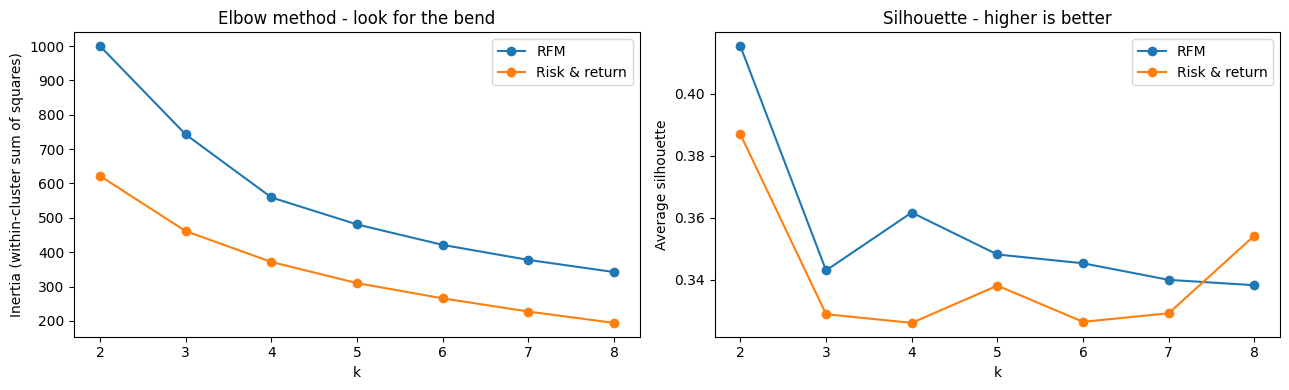

In [ ]:
rows = []
for name, X in MATRICES.items():
    for k in K_RANGE:
        km = kmeans(X, k)
        sizes = np.sort(np.bincount(km.labels_))[::-1]
        rows.append({"Matrix": name, "k": k, "Silhouette": silhouette_score(X, km.labels_),
                     "Inertia": km.inertia_, "Cluster sizes": [int(s) for s in sizes],
                     "Smallest": int(sizes.min())})
km_eval = pd.DataFrame(rows)
display(km_eval.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, g in km_eval.groupby("Matrix"):
    axes[0].plot(g["k"], g["Inertia"], marker="o", label=name)
    axes[1].plot(g["k"], g["Silhouette"], marker="o", label=name)
axes[0].set(xlabel="k", ylabel="Inertia (within-cluster sum of squares)",
            title="Elbow method - look for the bend")
axes[1].set(xlabel="k", ylabel="Average silhouette", title="Silhouette - higher is better")
for ax in axes: ax.legend()
plt.tight_layout(); plt.savefig("fig_2_3_kmeans_elbow_silhouette.png", dpi=150); plt.show()

In [ ]:
def profile(labels, cols):
    df = features[cols].copy()
    if "MeanWeeklyReturn" in df: df["MeanWeeklyReturn"] *= 100      # % per week
    if "Monetary" in df: df["Monetary"] /= 1e9                       # USD billions
    df["Cluster"] = labels
    out = df.groupby("Cluster")[[c for c in df.columns if c != "Cluster"]].median()
    out.insert(0, "Shares", df.groupby("Cluster").size())
    return out.round(3)

RR_COLS, RFM_COLS = ["MeanWeeklyReturn", "Beta"], ["Recency", "Frequency", "Monetary"]
SHOW_K = [3, 4, 5]

for k in SHOW_K:
    print(f"\n--- Risk & return, K-means, k = {k} (medians) ---")
    display(profile(kmeans(X_rr, k).labels_, RR_COLS))
    print(f"--- RFM, K-means, k = {k} (medians: R days, F days, M USD bn) ---")
    display(profile(kmeans(X_rfm, k).labels_, RFM_COLS))


--- Risk & return, K-means, k = 3 (medians) ---


,Shares,MeanWeeklyReturn,Beta
Cluster,,,
0,119,0.528,1.221
1,202,0.259,0.622
2,165,0.118,1.081


--- RFM, K-means, k = 3 (medians: R days, F days, M USD bn) ---


,Shares,Recency,Frequency,Monetary
Cluster,,,,
0,139,11.0,3.0,42.892
1,90,53.5,2.0,21.183
2,257,11.0,3.0,11.202



--- Risk & return, K-means, k = 4 (medians) ---


,Shares,MeanWeeklyReturn,Beta
Cluster,,,
0,160,0.432,0.982
1,41,0.687,1.677
2,132,0.113,1.142
3,153,0.186,0.575


... (2 outputs left out)


--- Risk & return, K-means, k = 5 (medians) ---


,Shares,MeanWeeklyReturn,Beta
Cluster,,,
0,165,0.415,0.999
1,114,0.072,0.978
2,28,0.823,1.482
3,124,0.210,0.519
4,55,0.253,1.501


--- RFM, K-means, k = 5 (medians: R days, F days, M USD bn) ---


,Shares,Recency,Frequency,Monetary
Cluster,,,,
0,40,11.0,4.0,87.552
1,119,11.0,4.0,12.696
2,87,54.0,2.0,21.053
3,141,11.0,3.0,10.138
4,99,11.0,2.0,34.321


In [ ]:
K_KM_RR  = 5
K_KM_RFM = 3

km_rr, km_rfm = kmeans(X_rr, K_KM_RR), kmeans(X_rfm, K_KM_RFM)

# Stability: rerun with 5 other seeds; ARI = 1 means identical memberships
for name, X, k, ref in [("Risk & return", X_rr, K_KM_RR, km_rr.labels_),
                        ("RFM", X_rfm, K_KM_RFM, km_rfm.labels_)]:
    ari = [adjusted_rand_score(ref, kmeans(X, k, seed=s).labels_) for s in [1, 7, 21, 99, 123]]
    print(f"{name}: ARI vs other seeds = {np.round(ari, 3).tolist()}")

pd.DataFrame({"KMeans_RR": km_rr.labels_ + 1, "KMeans_RFM": km_rfm.labels_ + 1},
             index=X_rr.index).to_csv("labels_kmeans.csv")
display(profile(km_rr.labels_ + 1, RR_COLS)); display(profile(km_rfm.labels_ + 1, RFM_COLS))

Risk & return: ARI vs other seeds = [0.857, 1.0, 0.888, 0.823, 0.856]
RFM: ARI vs other seeds = [1.0, 1.0, 1.0, 1.0, 1.0]


,Shares,MeanWeeklyReturn,Beta
Cluster,,,
1,165,0.415,0.999
2,114,0.072,0.978
3,28,0.823,1.482
4,124,0.210,0.519
5,55,0.253,1.501


,Shares,Recency,Frequency,Monetary
Cluster,,,,
1,139,11.0,3.0,42.892
2,90,53.5,2.0,21.183
3,257,11.0,3.0,11.202


In [ ]:
#Task 2.4
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score

features = pd.read_csv("feature_table.csv", index_col="Ticker")
X_rr  = pd.read_csv("X_risk_return_scaled.csv", index_col="Ticker")
X_rfm = pd.read_csv("X_rfm_scaled.csv", index_col="Ticker")
labels = pd.read_csv("labels_ward.csv", index_col="Ticker").join(
         pd.read_csv("labels_kmeans.csv", index_col="Ticker"))
features = features.loc[labels.index]
assert labels.index.equals(X_rr.index) and labels.index.equals(X_rfm.index)

# One table: every share, its five features, sector and its four cluster assignments
assignments = features[["Sector", "MeanWeeklyReturn", "Beta",
                        "Recency", "Frequency", "Monetary"]].join(labels)
assignments.to_csv("cluster_assignments.csv")
print("Shares:", len(assignments), "| Solutions:", list(labels.columns))

Shares: 486 | Solutions: ['Ward_RR', 'Ward_RFM', 'KMeans_RR', 'KMeans_RFM']


In [ ]:
def profile(sol, cols):
    df = assignments[cols + [sol]].copy()
    if "MeanWeeklyReturn" in df: df["MeanWeeklyReturn"] *= 100      # % per week
    if "Monetary" in df: df["Monetary"] /= 1e9                       # USD billions
    out = df.groupby(sol)[cols].median()
    out.insert(0, "Shares", df.groupby(sol).size())
    return out.round(3)

RR_COLS, RFM_COLS = ["MeanWeeklyReturn", "Beta"], ["Recency", "Frequency", "Monetary"]
profiles = {}
for sol, cols in [("Ward_RR", RR_COLS), ("KMeans_RR", RR_COLS),
                  ("Ward_RFM", RFM_COLS), ("KMeans_RFM", RFM_COLS)]:
    profiles[sol] = profile(sol, cols)
    print(f"\n{sol}  (return % per week, R days, F days, M USD bn - medians)")
    display(profiles[sol])
pd.concat(profiles, names=["Solution"]).to_csv("cluster_profiles.csv")


Ward_RR  (return % per week, R days, F days, M USD bn - medians)


,Shares,MeanWeeklyReturn,Beta
Ward_RR,,,
1,92,0.550,1.218
2,66,0.113,0.449
3,98,0.392,0.666
4,48,0.252,1.514
5,182,0.166,0.964



KMeans_RR  (return % per week, R days, F days, M USD bn - medians)


,Shares,MeanWeeklyReturn,Beta
KMeans_RR,,,
1,165,0.415,0.999
2,114,0.072,0.978
3,28,0.823,1.482
4,124,0.210,0.519
5,55,0.253,1.501



Ward_RFM  (return % per week, R days, F days, M USD bn - medians)


,Shares,Recency,Frequency,Monetary
Ward_RFM,,,,
1,106,46.5,2.0,19.485
2,141,11.0,3.0,42.013
3,239,11.0,3.0,11.154



KMeans_RFM  (return % per week, R days, F days, M USD bn - medians)


,Shares,Recency,Frequency,Monetary
KMeans_RFM,,,,
1,139,11.0,3.0,42.892
2,90,53.5,2.0,21.183
3,257,11.0,3.0,11.202


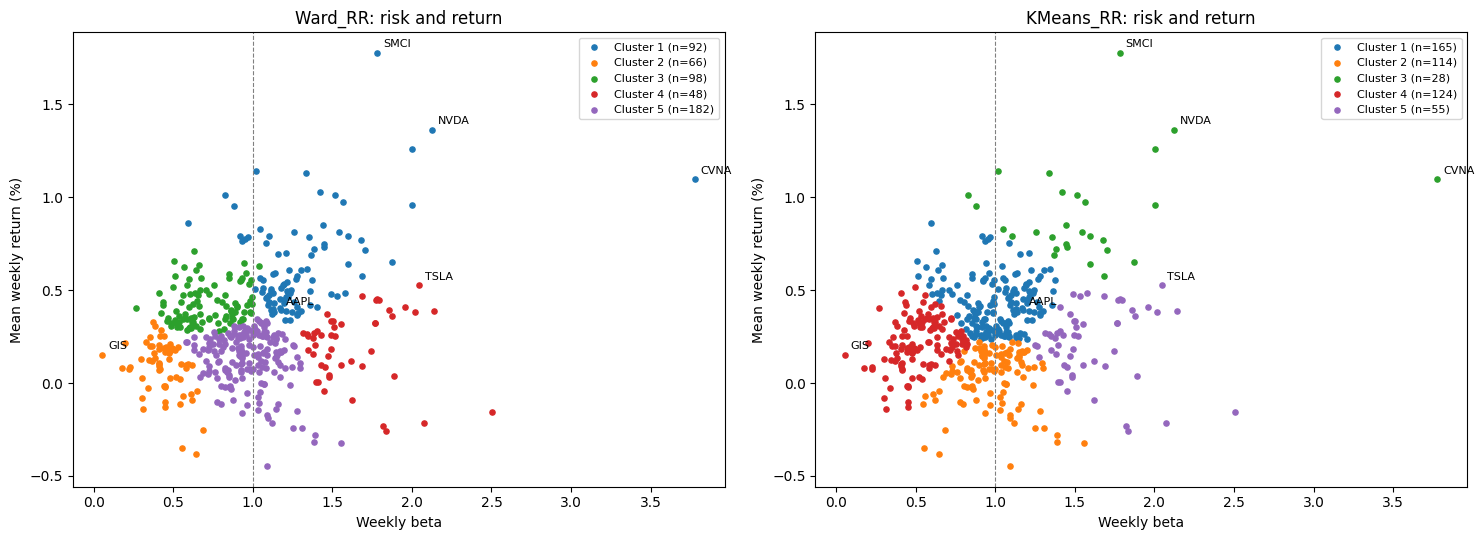

Variance explained: PC1 43.6%, PC2 33.6%, total 77.2%
PCA loadings (how each standardised feature builds each axis):


,PC1,PC2
log1p_Recency,0.712,0.027
Frequency,-0.649,0.405
log1p_Monetary,0.266,0.914


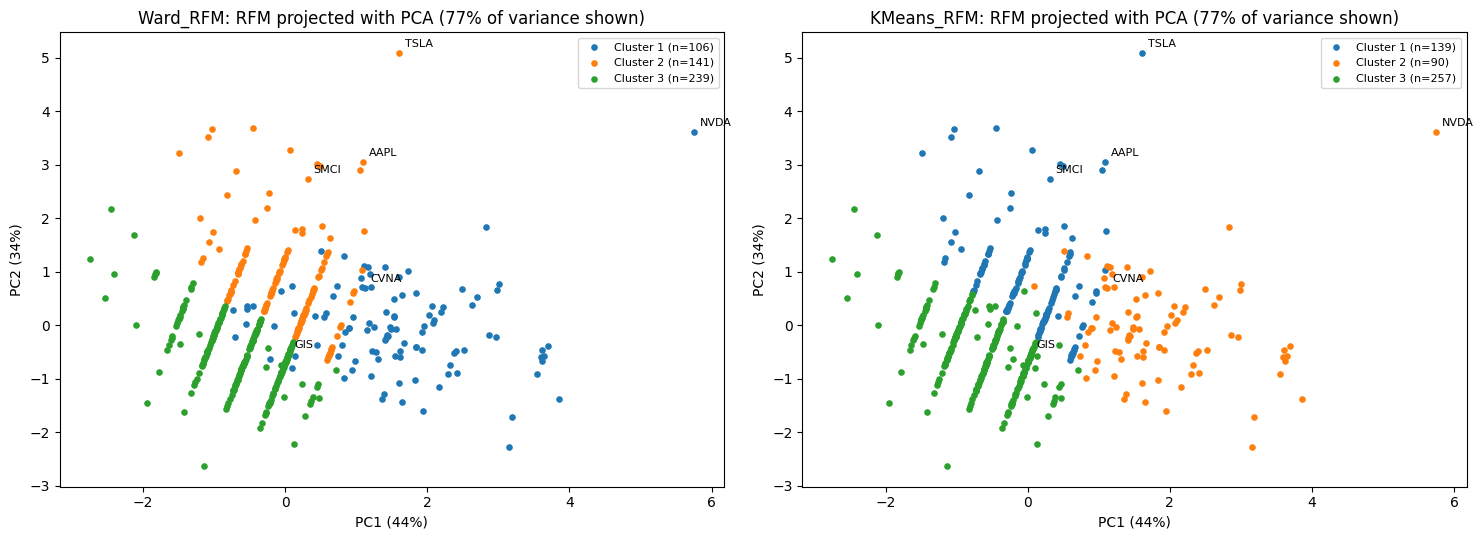

In [ ]:
LABEL_THESE = ["CVNA", "SMCI", "NVDA", "TSLA", "AAPL", "GIS"]    # notable shares to name

# Risk & return has only two features, so it is plotted directly in original units
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, sol in zip(axes, ["Ward_RR", "KMeans_RR"]):
    for c, g in assignments.groupby(sol):
        ax.scatter(g["Beta"], g["MeanWeeklyReturn"] * 100, s=14, label=f"Cluster {c} (n={len(g)})")
    for t in [t for t in LABEL_THESE if t in assignments.index]:
        ax.annotate(t, (assignments.loc[t, "Beta"], assignments.loc[t, "MeanWeeklyReturn"] * 100),
                    fontsize=8, xytext=(4, 4), textcoords="offset points")
    ax.axvline(1, color="grey", lw=0.8, ls="--")                   # beta = 1: moves with market
    ax.set(title=f"{sol}: risk and return", xlabel="Weekly beta",
           ylabel="Mean weekly return (%)")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("fig_2_4_risk_return_clusters.png", dpi=150); plt.show()

# RFM has three features, so PCA projects them onto the two directions of greatest spread
pca = PCA(n_components=2, random_state=42).fit(X_rfm)
pcs = pd.DataFrame(pca.transform(X_rfm), index=X_rfm.index, columns=["PC1", "PC2"])
var = pca.explained_variance_ratio_
print("Variance explained: PC1 {:.1%}, PC2 {:.1%}, total {:.1%}".format(var[0], var[1], var.sum()))
print("PCA loadings (how each standardised feature builds each axis):")
display(pd.DataFrame(pca.components_.T, index=X_rfm.columns, columns=["PC1", "PC2"]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, sol in zip(axes, ["Ward_RFM", "KMeans_RFM"]):
    for c, g in assignments.groupby(sol):
        ax.scatter(pcs.loc[g.index, "PC1"], pcs.loc[g.index, "PC2"], s=14,
                   label=f"Cluster {c} (n={len(g)})")
    for t in [t for t in LABEL_THESE if t in pcs.index]:
        ax.annotate(t, pcs.loc[t], fontsize=8, xytext=(4, 4), textcoords="offset points")
    ax.set(title=f"{sol}: RFM projected with PCA ({var.sum():.0%} of variance shown)",
           xlabel=f"PC1 ({var[0]:.0%})", ylabel=f"PC2 ({var[1]:.0%})")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("fig_2_4_rfm_clusters_pca.png", dpi=150); plt.show()

In [ ]:
for name, a, b, X in [("Risk & return", "Ward_RR", "KMeans_RR", X_rr),
                      ("RFM", "Ward_RFM", "KMeans_RFM", X_rfm)]:
    ari = adjusted_rand_score(assignments[a], assignments[b])
    print(f"\n{name}: ARI Ward vs K-means = {ari:.3f} | silhouette Ward "
          f"{silhouette_score(X, assignments[a]):.3f}, K-means {silhouette_score(X, assignments[b]):.3f}")
    print("Rows = Ward cluster, columns = K-means cluster, values = number of shares")
    display(pd.crosstab(assignments[a], assignments[b], margins=True))


Risk & return: ARI Ward vs K-means = 0.329 | silhouette Ward 0.304, K-means 0.338
Rows = Ward cluster, columns = K-means cluster, values = number of shares


KMeans_RR,1,2,3,4,5,All
Ward_RR,,,,,,
1,60,0,28,0,4,92
2,0,8,0,58,0,66
3,56,0,0,42,0,98
4,0,0,0,0,48,48
5,49,106,0,24,3,182
All,165,114,28,124,55,486



RFM: ARI Ward vs K-means = 0.876 | silhouette Ward 0.335, K-means 0.343
Rows = Ward cluster, columns = K-means cluster, values = number of shares


KMeans_RFM,1,2,3,All
Ward_RFM,,,,
1,3,90,13,106
2,136,0,5,141
3,0,0,239,239
All,139,90,257,486


In [ ]:
#Task 2.5
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score, silhouette_score

assignments = pd.read_csv("cluster_assignments.csv", index_col="Ticker")
X_rfm = pd.read_csv("X_rfm_scaled.csv", index_col="Ticker").loc[assignments.index]

corr_in = pd.DataFrame({"Recency": assignments["Recency"],
                        "Frequency": assignments["Frequency"],
                        "log1p(M)": np.log1p(assignments["Monetary"])})
print("Pearson correlation (straight-line relationship):")
display(corr_in.corr(method="pearson").round(3))
print("Spearman correlation (rank order - less affected by skew and ties):")
display(corr_in.corr(method="spearman").round(3))
print("Correlation of the features exactly as clustered (standardised):")
display(X_rfm.corr().round(3))

Pearson correlation (straight-line relationship):


,Recency,Frequency,log1p(M)
Recency,1.000,-0.346,0.152
Frequency,-0.346,1.000,0.013
log1p(M),0.152,0.013,1.000


Spearman correlation (rank order - less affected by skew and ties):


,Recency,Frequency,log1p(M)
Recency,1.000,-0.196,0.137
Frequency,-0.196,1.000,-0.048
log1p(M),0.137,-0.048,1.000


Correlation of the features exactly as clustered (standardised):


,log1p_Recency,Frequency,log1p_Monetary
log1p_Recency,1.000,-0.285,0.127
Frequency,-0.285,1.000,0.013
log1p_Monetary,0.127,0.013,1.000


In [ ]:
K_WARD_RFM = assignments["Ward_RFM"].nunique()                   # the selected cluster count
rf_cols = [c for c in X_rfm.columns if "Monetary" not in c]      # Recency (as used) + Frequency

# Standardise the reduced matrix afresh, as the brief requires
rf_raw = pd.DataFrame({"Recency": assignments["Recency"], "Frequency": assignments["Frequency"]})
if any("log1p_Recency" == c for c in rf_cols):
    rf_raw["Recency"] = np.log1p(rf_raw["Recency"])               # same treatment as before
X_rf = pd.DataFrame(StandardScaler().fit_transform(rf_raw), index=rf_raw.index,
                    columns=rf_raw.columns)

ward_rf = fcluster(linkage(X_rf.values, method="ward", metric="euclidean"),
                   t=K_WARD_RFM, criterion="maxclust")
assignments["Ward_RF_noM"] = ward_rf

ari = adjusted_rand_score(assignments["Ward_RFM"], assignments["Ward_RF_noM"])
print(f"k = {K_WARD_RFM} | ARI full RFM vs R+F only = {ari:.3f} "
      "(1 = identical memberships, about 0 = no better than chance)")
print(f"Silhouette R+F only: {silhouette_score(X_rf, ward_rf):.3f}")
print("\nRows = full RFM cluster, columns = R+F-only cluster:")
display(pd.crosstab(assignments["Ward_RFM"], assignments["Ward_RF_noM"], margins=True))

# Traded value profiles: does M mainly separate liquidity levels?
def m_profile(sol):
    g = assignments.groupby(sol)
    return pd.DataFrame({"Shares": g.size(), "Median R": g["Recency"].median(),
                         "Median F": g["Frequency"].median(),
                         "Median M (USD bn)": g["Monetary"].median() / 1e9,
                         "Mean M (USD bn)": g["Monetary"].mean() / 1e9}).round(2)

print("\nWith Monetary (selected Ward RFM solution):"); display(m_profile("Ward_RFM"))
print("Without Monetary (R and F only):");                display(m_profile("Ward_RF_noM"))
assignments.to_csv("cluster_assignments.csv")

k = 3 | ARI full RFM vs R+F only = 0.349 (1 = identical memberships, about 0 = no better than chance)
Silhouette R+F only: 0.508

Rows = full RFM cluster, columns = R+F-only cluster:


Ward_RF_noM,1,2,3,All
Ward_RFM,,,,
1,101,0,5,106
2,8,59,74,141
3,0,66,173,239
All,109,125,252,486



With Monetary (selected Ward RFM solution):


,Shares,Median R,Median F,Median M (USD bn),Mean M (USD bn)
Ward_RFM,,,,,
1,106,46.5,2.0,19.49,42.04
2,141,11.0,3.0,42.01,84.42
3,239,11.0,3.0,11.15,11.68


Without Monetary (R and F only):


,Shares,Median R,Median F,Median M (USD bn),Mean M (USD bn)
Ward_RF_noM,,,,,
1,109,46.0,2.0,20.85,66.94
2,125,11.0,2.0,17.70,34.34
3,252,11.0,4.0,14.74,30.01



Ward_RR: % of each cluster from each sector


Ward_RR,1,2,3,4,5
Sector,,,,,
Communication Services,5.4,4.5,5.1,0.0,3.8
Consumer Discretionary,12.0,0.0,9.2,20.8,9.3
Consumer Staples,0.0,33.3,5.1,0.0,2.7
Energy,4.3,0.0,16.3,0.0,0.0
Financials,14.1,3.0,28.6,10.4,14.3
Health Care,2.2,28.8,8.2,8.3,13.7
Industrials,22.8,3.0,11.2,8.3,22.0
Information Technology,31.5,0.0,2.0,47.9,11.0
Materials,3.3,1.5,3.1,4.2,7.7


Ward_RR: most over-represented sector in each cluster (lift = cluster % / overall %)


,Top sector,Lift,Cluster size
Ward_RR,,,
1,Information Technology,2.07,92
2,Consumer Staples,5.06,66
3,Energy,3.97,98
4,Information Technology,3.15,48
5,Real Estate,2.05,182



KMeans_RR: % of each cluster from each sector


KMeans_RR,1,2,3,4,5
Sector,,,,,
Communication Services,4.8,4.4,0.0,4.8,1.8
Consumer Discretionary,12.1,9.6,10.7,1.6,20.0
Consumer Staples,1.2,6.1,0.0,18.5,0.0
Energy,9.7,0.0,7.1,1.6,0.0
Financials,22.4,8.8,14.3,13.7,10.9
Health Care,4.8,21.1,0.0,17.7,7.3
Industrials,20.6,19.3,21.4,9.7,7.3
Information Technology,13.3,9.6,39.3,2.4,49.1
Materials,3.0,8.8,3.6,4.0,3.6


... (6 outputs left out)


KMeans_RFM: % of each cluster from each sector


KMeans_RFM,1,2,3
Sector,,,
Communication Services,6.5,2.2,3.5
Consumer Discretionary,12.9,12.2,7.0
Consumer Staples,6.5,7.8,6.2
Energy,7.2,2.2,3.1
Financials,15.1,14.4,15.6
Health Care,14.4,10.0,11.3
Industrials,12.2,11.1,19.8
Information Technology,20.9,22.2,9.7
Materials,1.4,7.8,5.4


KMeans_RFM: most over-represented sector in each cluster (lift = cluster % / overall %)


,Top sector,Lift,Cluster size
KMeans_RFM,,,
1,Energy,1.75,139
2,Materials,1.64,90
3,Real Estate,1.70,257


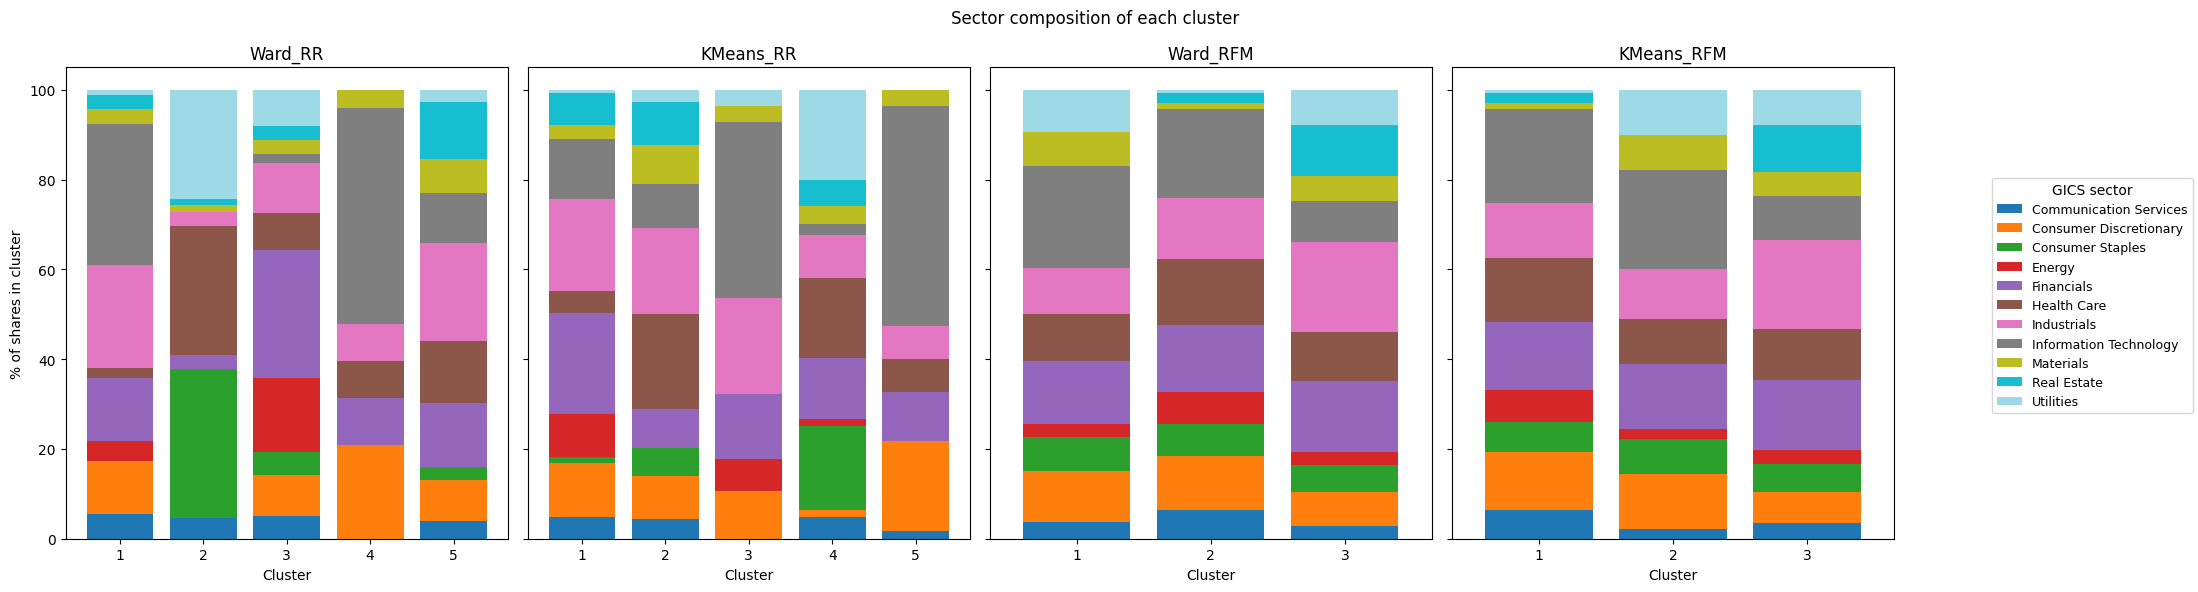

In [ ]:
# Task 3.2.1
import pandas as pd
import matplotlib.pyplot as plt

assignments = pd.read_csv("cluster_assignments.csv", index_col="Ticker")
SOLUTIONS = ["Ward_RR", "KMeans_RR", "Ward_RFM", "KMeans_RFM"]
overall = assignments["Sector"].value_counts(normalize=True)          # sector mix of all 486

sector_tables = {}
for sol in SOLUTIONS:
    counts = pd.crosstab(assignments["Sector"], assignments[sol])
    share = counts / counts.sum()                                     # % of each cluster
    lift = share.div(overall, axis=0)                                 # >1 = over-represented
    sector_tables[sol] = share
    print(f"\n{sol}: % of each cluster from each sector")
    display((share * 100).round(1))
    print(f"{sol}: most over-represented sector in each cluster (lift = cluster % / overall %)")
    top = lift.idxmax()
    display(pd.DataFrame({"Top sector": top,
                          "Lift": [round(lift.loc[s, c], 2) for c, s in top.items()],
                          "Cluster size": counts.sum()}))

fig, axes = plt.subplots(1, 4, figsize=(22, 6), sharey=True)
for ax, sol in zip(axes, SOLUTIONS):
    (sector_tables[sol].T * 100).plot.bar(stacked=True, ax=ax, legend=False, width=0.8,
                                          colormap="tab20")
    ax.set(title=sol, xlabel="Cluster", ylabel="% of shares in cluster")
    ax.tick_params(axis="x", rotation=0)
handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, names, loc="center right", fontsize=9, title="GICS sector")
fig.suptitle("Sector composition of each cluster")
plt.tight_layout(rect=[0, 0, 0.87, 1]); plt.savefig("fig_3_2_sector_composition.png", dpi=150)
plt.show()

pd.concat(sector_tables, names=["Solution", "Sector"]).to_csv("sector_composition.csv")